# Install Required Libraries

In [1]:
!pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn scipy

# Import Libraries

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


# Download Dataset from Kaggle

In [3]:
path = kagglehub.dataset_download("uciml/iris")

print("Dataset downloaded successfully!")
print("Dataset Path:", path)

Using Colab cache for faster access to the 'iris' dataset.
Dataset downloaded successfully!
Dataset Path: /kaggle/input/iris


# Load Dataset

In [4]:
data_path = Path(path)

csv_files = list(data_path.glob("*.csv"))

df = pd.read_csv(csv_files[0])

print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


# Dataset Information

In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 6)

Column Names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


# Statistical Analysis

In [6]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


# Check Missing Values

In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


# Check Species Distribution

In [8]:
print("Species Distribution:")
print(df["Species"].value_counts())

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


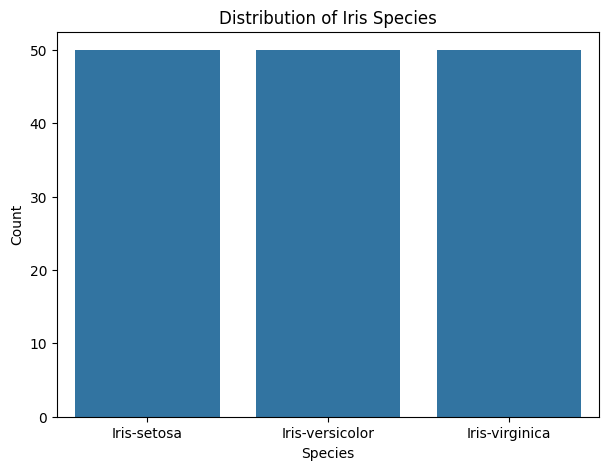

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

# Data Preprocessing

In [10]:
df = df.drop(columns=["Id"], errors="ignore")

X = df.drop(columns=["Species"])

y = df["Species"]

print("Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

Features:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

Target Classes:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


# Feature Scaling

In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Scaled Data:")
X_scaled.head()

Scaled Data:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


# Calculate Distance Matrix

In [12]:
distance_matrix = squareform(
    pdist(X_scaled, metric="euclidean")
)

distance_df = pd.DataFrame(
    distance_matrix
)

print("Distance Matrix Shape:", distance_df.shape)

distance_df.iloc[:10, :10]

Distance Matrix Shape: (150, 150)


,0,1,2,3,4,5,6,7,8,9
0,0.000000,1.182121,0.848567,1.107715,0.261207,1.042658,0.661720,0.267325,1.626993,0.967472
1,1.182121,0.000000,0.525499,0.434645,1.393695,2.191488,1.003084,0.935239,0.648528,0.272151
2,0.848567,0.525499,0.000000,0.284893,0.996055,1.861209,0.499389,0.599382,0.785681,0.377484
3,1.107715,0.434645,0.284893,0.000000,1.255716,2.109201,0.708833,0.846660,0.525499,0.386549
4,0.261207,1.393695,0.996055,1.255716,0.000000,0.902816,0.682921,0.466286,1.775488,1.172128
5,1.042658,2.191488,1.861209,2.109201,0.902816,0.000000,1.524696,1.286727,2.630806,1.990621
6,0.661720,1.003084,0.499389,0.708833,0.682921,1.524696,0.000000,0.505396,1.189410,0.828514
7,0.267325,0.935239,0.599382,0.846660,0.466286,1.286727,0.505396,0.000000,1.367646,0.716863
8,1.626993,0.648528,0.785681,0.525499,1.775488,2.630806,1.189410,1.367646,0.000000,0.775725
9,0.967472,0.272151,0.377484,0.386549,1.172128,1.990621,0.828514,0.716863,0.775725,0.000000


# Distance Matrix Visualization

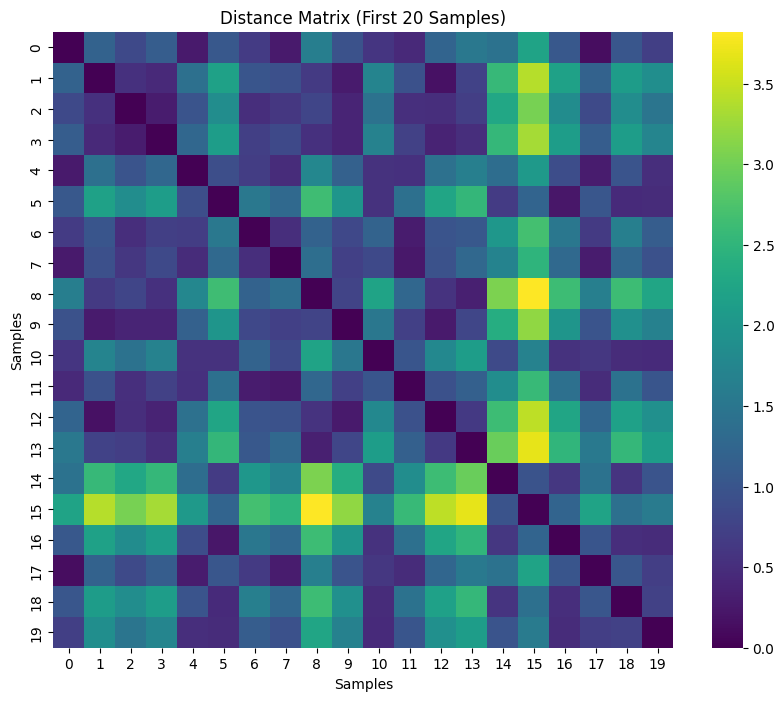

In [13]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    distance_df.iloc[:20, :20],
    cmap="viridis"
)

plt.title("Distance Matrix (First 20 Samples)")
plt.xlabel("Samples")
plt.ylabel("Samples")

plt.show()

# Hierarchical Clustering Using Single Linkage

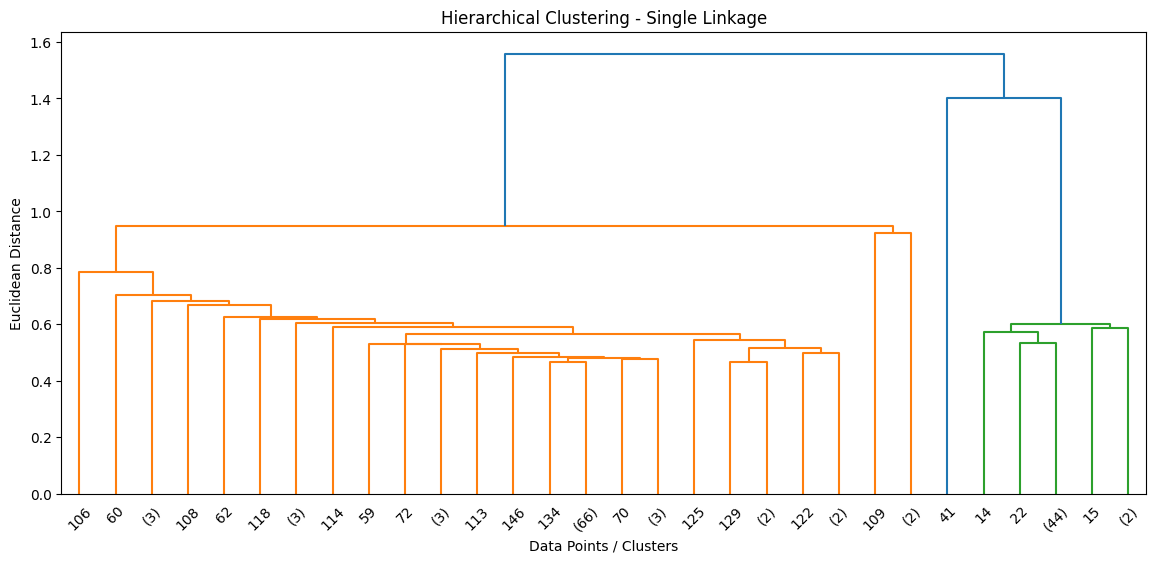

In [14]:
Z_single = linkage(
    X_scaled,
    method="single",
    metric="euclidean"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z_single,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering - Single Linkage")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Euclidean Distance")

plt.show()

# Hierarchical Clustering Using Complete Linkage

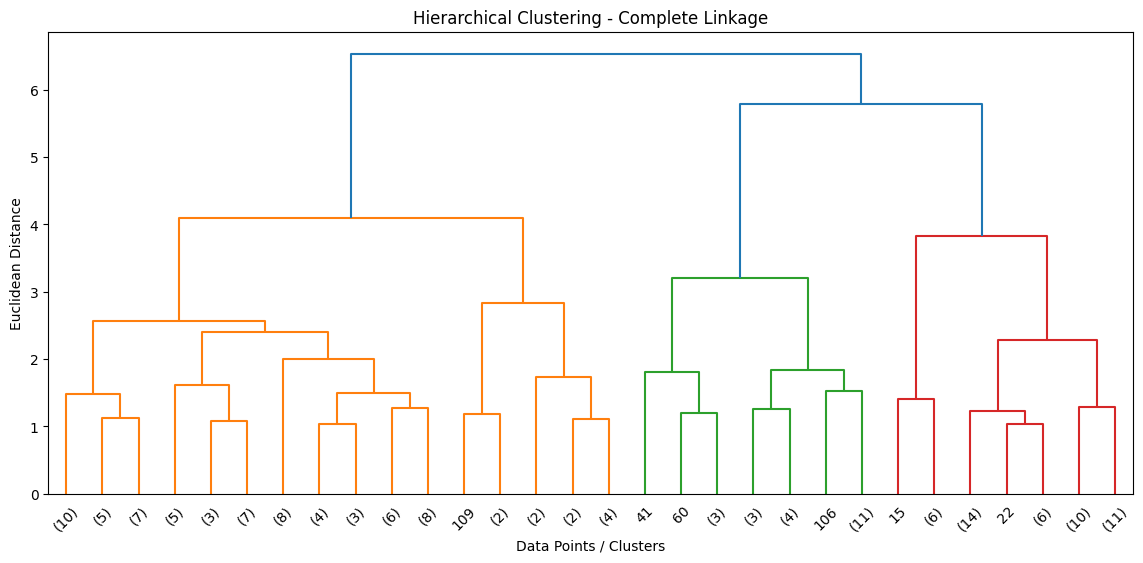

In [15]:
Z_complete = linkage(
    X_scaled,
    method="complete",
    metric="euclidean"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z_complete,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering - Complete Linkage")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Euclidean Distance")

plt.show()

# Hierarchical Clustering Using Average Linkage

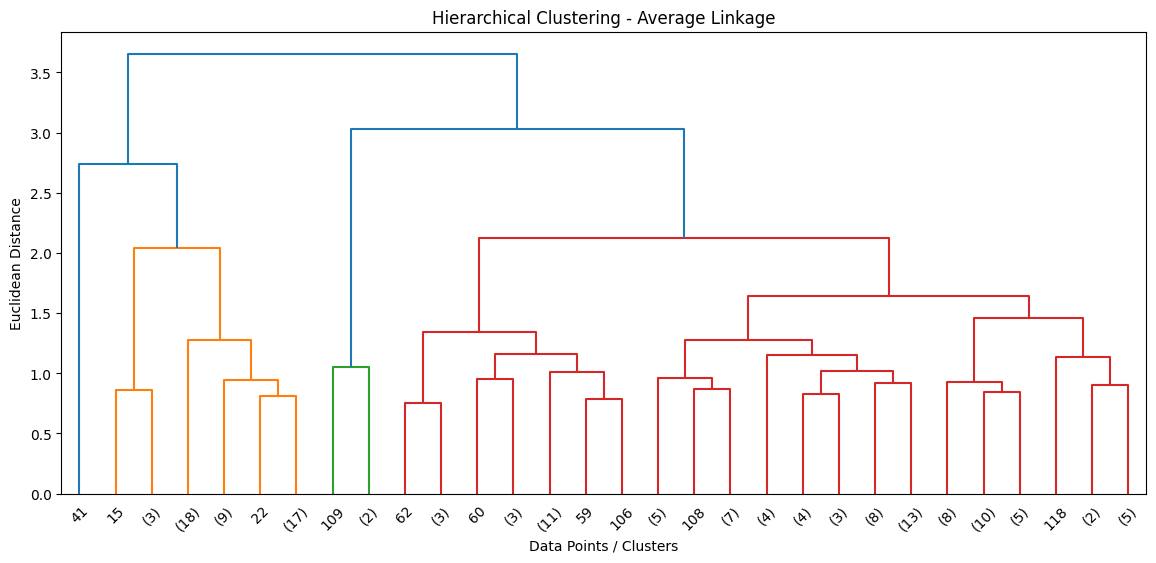

In [16]:
Z_average = linkage(
    X_scaled,
    method="average",
    metric="euclidean"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z_average,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering - Average Linkage")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Euclidean Distance")

plt.show()

# Hierarchical Clustering Using Ward Linkage

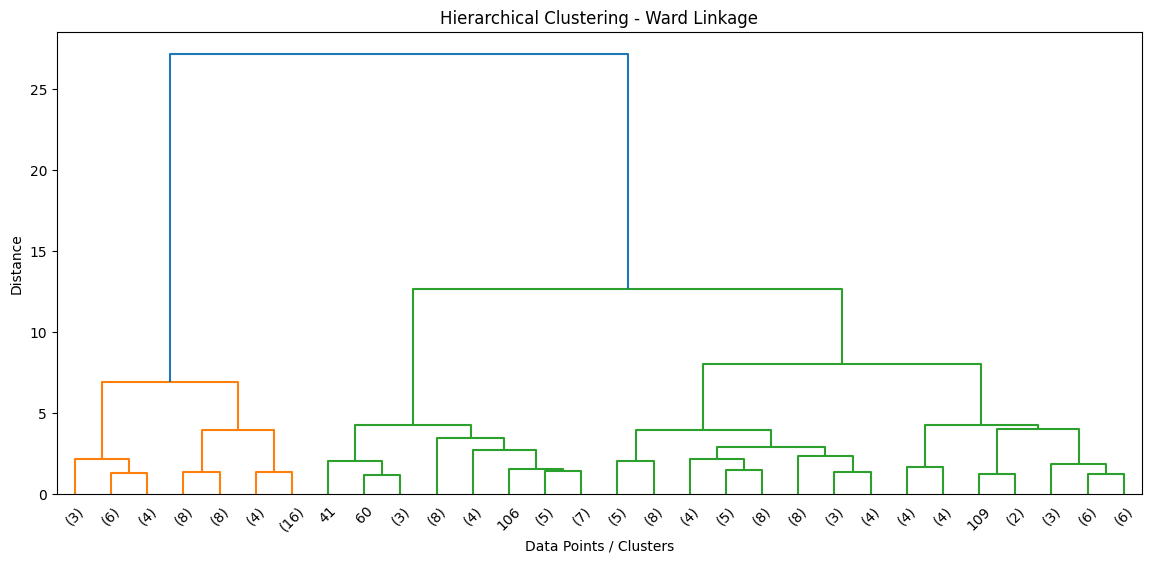

In [17]:
Z_ward = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering - Ward Linkage")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Distance")

plt.show()

# Compare Different Linkage Methods

In [18]:
linkage_methods = [
    "single",
    "complete",
    "average",
    "ward"
]

results = {}

for method in linkage_methods:

    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method,
        metric="euclidean"
    )

    labels = model.fit_predict(X_scaled)

    results[method] = labels

    print(f"\nLinkage Method: {method}")
    print("Cluster Labels:", np.unique(labels))
    print("Cluster Sizes:", pd.Series(labels).value_counts().sort_index().to_dict())


Linkage Method: single
Cluster Labels: [0 1 2]
Cluster Sizes: {0: 100, 1: 1, 2: 49}

Linkage Method: complete
Cluster Labels: [0 1 2]
Cluster Sizes: {0: 77, 1: 49, 2: 24}

Linkage Method: average
Cluster Labels: [0 1 2]
Cluster Sizes: {0: 50, 1: 97, 2: 3}

Linkage Method: ward
Cluster Labels: [0 1 2]
Cluster Sizes: {0: 71, 1: 49, 2: 30}


# Calculate Silhouette Score

In [19]:
silhouette_results = {}

for method, labels in results.items():

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_results[method] = score

    print(f"{method}: {score:.4f}")

single: 0.5029
complete: 0.4488
average: 0.4795
ward: 0.4455


# Calculate Adjusted Rand Index (ARI)

In [20]:
ari_results = {}

for method, labels in results.items():

    score = adjusted_rand_score(
        y,
        labels
    )

    ari_results[method] = score

    print(f"{method}: {score:.4f}")

single: 0.5584
complete: 0.5726
average: 0.5621
ward: 0.6153


# Performance Comparison

In [21]:
comparison = pd.DataFrame({
    "Linkage": linkage_methods,
    "Silhouette Score": [
        silhouette_results[m] for m in linkage_methods
    ],
    "ARI Score": [
        ari_results[m] for m in linkage_methods
    ]
})

comparison

,Linkage,Silhouette Score,ARI Score
0,single,0.502877,0.558371
1,complete,0.448791,0.572631
2,average,0.479451,0.562136
3,ward,0.445540,0.615323


# Visual Comparison

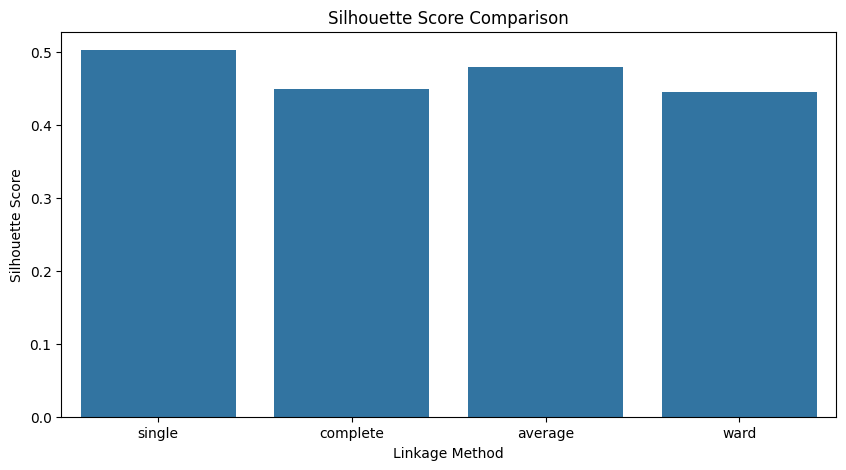

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Linkage",
    y="Silhouette Score"
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Linkage Method")
plt.ylabel("Silhouette Score")

plt.show()

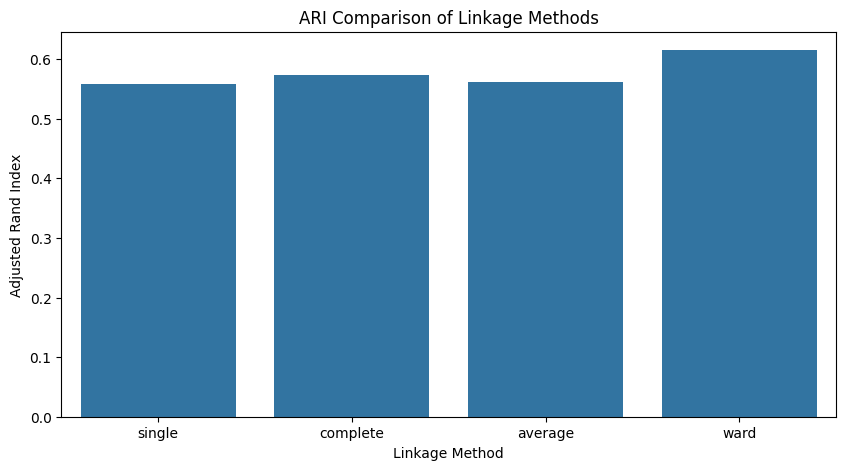

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Linkage",
    y="ARI Score"
)

plt.title("ARI Comparison of Linkage Methods")
plt.xlabel("Linkage Method")
plt.ylabel("Adjusted Rand Index")

plt.show()

# Visualize Clusters Using PCA

In [24]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.72770452 0.23030523]

Total Explained Variance:
0.9580097536148199


Single Linkage

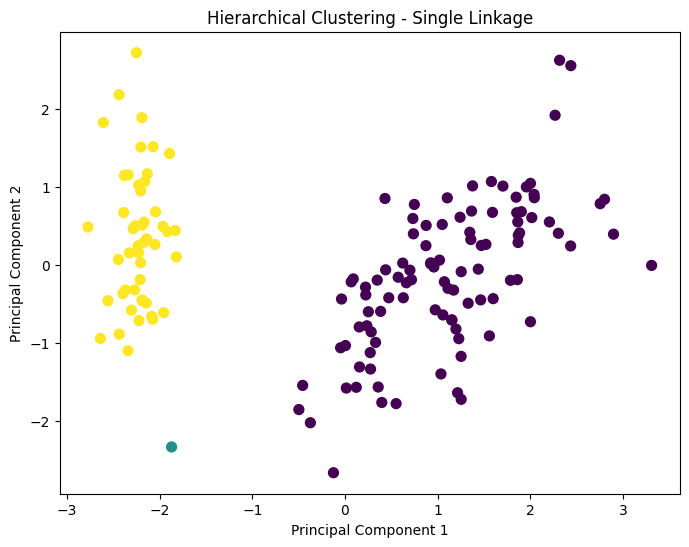

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=results["single"],
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering - Single Linkage")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

Complete Linkage

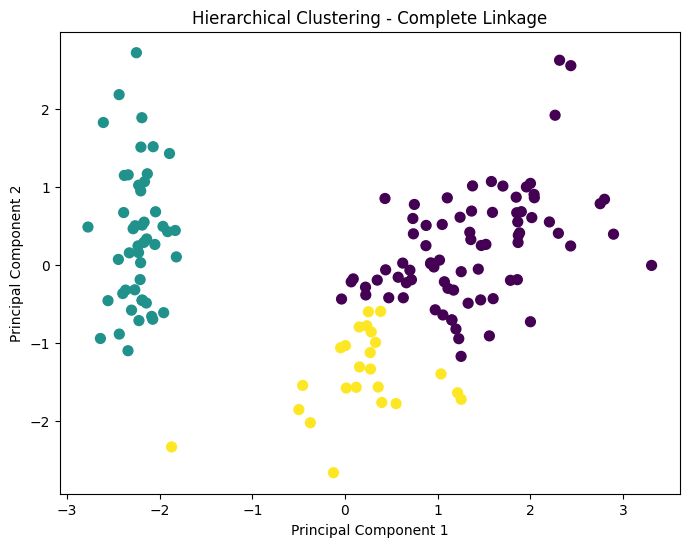

In [26]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=results["complete"],
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering - Complete Linkage")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

Average Linkage

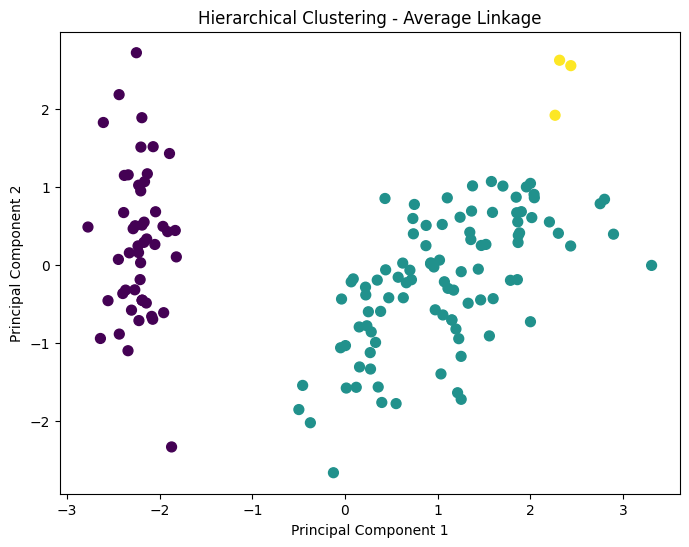

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=results["average"],
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering - Average Linkage")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

Ward Linkage

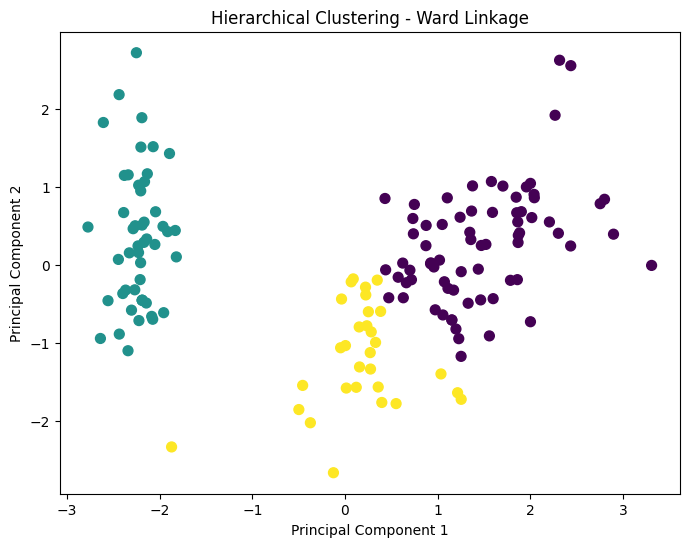

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=results["ward"],
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering - Ward Linkage")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

# Compare Actual Species with Clusters

In [29]:
for method in linkage_methods:

    print(f"\n===== {method.upper()} LINKAGE =====")

    cluster_comparison = pd.crosstab(
        y,
        results[method],
        rownames=["Actual Species"],
        colnames=["Predicted Cluster"]
    )

    display(cluster_comparison)


===== SINGLE LINKAGE =====


Predicted Cluster,0,1,2
Actual Species,,,
Iris-setosa,0,1,49
Iris-versicolor,50,0,0
Iris-virginica,50,0,0



===== COMPLETE LINKAGE =====


Predicted Cluster,0,1,2
Actual Species,,,
Iris-setosa,0,49,1
Iris-versicolor,29,0,21
Iris-virginica,48,0,2



===== AVERAGE LINKAGE =====


Predicted Cluster,0,1,2
Actual Species,,,
Iris-setosa,50,0,0
Iris-versicolor,0,50,0
Iris-virginica,0,47,3



===== WARD LINKAGE =====


Predicted Cluster,0,1,2
Actual Species,,,
Iris-setosa,0,49,1
Iris-versicolor,23,0,27
Iris-virginica,48,0,2


Heatmap Comparison

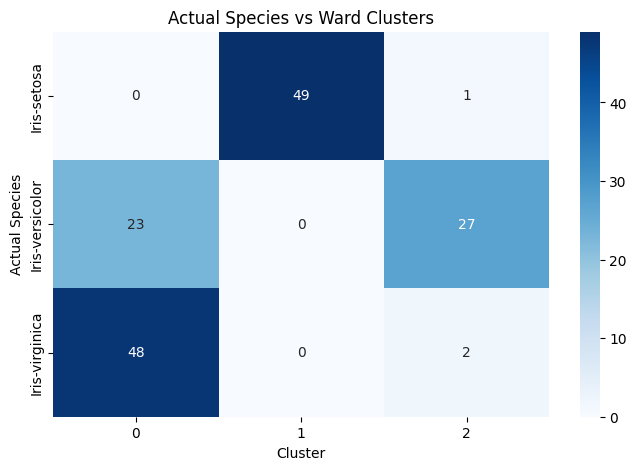

In [30]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    pd.crosstab(y, results["ward"]),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Species vs Ward Clusters")
plt.xlabel("Cluster")
plt.ylabel("Actual Species")

plt.show()

Actual Species Visualization

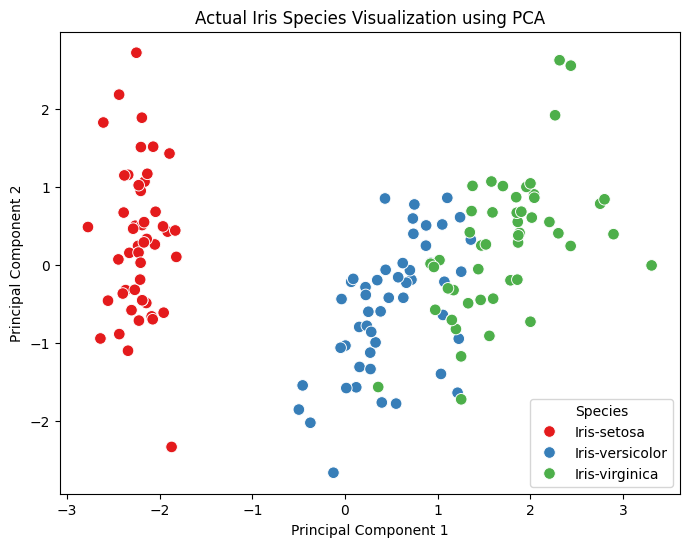

In [31]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette="Set1",
    s=70
)

plt.title("Actual Iris Species Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

# Cluster Distribution

In [32]:
for method in linkage_methods:

    print(f"\n{method.upper()} Linkage Cluster Distribution:")

    cluster_counts = pd.Series(
        results[method]
    ).value_counts().sort_index()

    print(cluster_counts)


SINGLE Linkage Cluster Distribution:
0    100
1      1
2     49
Name: count, dtype: int64

COMPLETE Linkage Cluster Distribution:
0    77
1    49
2    24
Name: count, dtype: int64

AVERAGE Linkage Cluster Distribution:
0    50
1    97
2     3
Name: count, dtype: int64

WARD Linkage Cluster Distribution:
0    71
1    49
2    30
Name: count, dtype: int64


# Find the Best Linkage Method

In [33]:
best_method = max(
    silhouette_results,
    key=silhouette_results.get
)

print("Best Linkage Method:", best_method)

print(
    "Best Silhouette Score:",
    silhouette_results[best_method]
)

print(
    "Best ARI Score:",
    ari_results[best_method]
)

Best Linkage Method: single
Best Silhouette Score: 0.5028765952374756
Best ARI Score: 0.5583714437541352


# Final Result Visualization

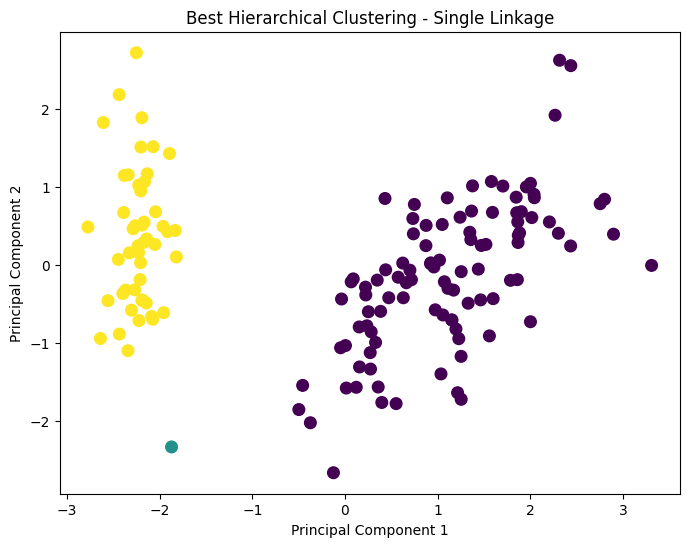

In [34]:
best_labels = results[best_method]

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=best_labels,
    cmap="viridis",
    s=70
)

plt.title(f"Best Hierarchical Clustering - {best_method.title()} Linkage")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

# Save Experimental Results

In [35]:
final_results = df.copy()

for method in linkage_methods:

    final_results[f"{method}_cluster"] = results[method]

final_results["best_cluster"] = best_labels

final_results.to_csv(
    "hierarchical_clustering_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


# Save Performance Comparison

In [36]:
comparison.to_csv(
    "linkage_comparison.csv",
    index=False
)

print("Comparison CSV saved!")

Comparison CSV saved!


# Download CSV from Google Colab

In [37]:
from google.colab import files

files.download("hierarchical_clustering_results.csv")

files.download("linkage_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Final Conclusion

In [38]:
print("========== FINAL CONCLUSION ==========")

print("Algorithm: Hierarchical Clustering")
print("Dataset: Iris Dataset")
print("Number of Clusters: 3")
print("Distance Metric: Euclidean")

print("\nLinkage Comparison:")
display(comparison)

print("\nBest Linkage Method:", best_method)
print("Silhouette Score:", silhouette_results[best_method])
print("ARI Score:", ari_results[best_method])

print("\nExperiment Completed Successfully!")

========== FINAL CONCLUSION ==========
Algorithm: Hierarchical Clustering
Dataset: Iris Dataset
Number of Clusters: 3
Distance Metric: Euclidean

Linkage Comparison:


,Linkage,Silhouette Score,ARI Score
0,single,0.502877,0.558371
1,complete,0.448791,0.572631
2,average,0.479451,0.562136
3,ward,0.445540,0.615323



Best Linkage Method: single
Silhouette Score: 0.5028765952374756
ARI Score: 0.5583714437541352

Experiment Completed Successfully!


# Hierarchical Clustering

## 1. Introduction

Hierarchical Clustering is an **Unsupervised Machine Learning algorithm** used to group similar data points into clusters.

It creates a hierarchy of clusters in the form of a tree-like structure called a **Dendrogram**.

- It does not require predefined class labels.
- It groups similar data points together.
- It shows the relationship between different clusters.
- It can help determine the number of clusters using a Dendrogram.

**Example:** Grouping customers based on their purchasing behavior.

---

## 2. Types of Hierarchical Clustering

There are two main types of Hierarchical Clustering:

### 2.1 Agglomerative Clustering (Bottom-Up)

Agglomerative Clustering starts with each data point as a separate cluster.

Then, it repeatedly merges the closest clusters until all data points become one cluster or the required number of clusters is reached.

**Steps:**

1. Initially, each data point forms a separate cluster.
2. Calculate the distance between clusters.
3. Find the two closest clusters.
4. Merge those two clusters.
5. Repeat the process until the stopping condition is reached.

**Example:**

Suppose we have four data points: A, B, C, and D.

Initially:

- Cluster 1 = {A}
- Cluster 2 = {B}
- Cluster 3 = {C}
- Cluster 4 = {D}

If A and B are closest, they are merged.

- Cluster 1 = {A, B}
- Cluster 2 = {C}
- Cluster 3 = {D}

The process continues until the required clusters are formed.

### 2.2 Divisive Clustering (Top-Down)

Divisive Clustering starts with all data points in one single cluster.

Then, it repeatedly divides the cluster into smaller clusters.

**Steps:**

1. Put all data points into one cluster.
2. Divide the cluster into smaller groups.
3. Continue dividing the clusters.
4. Stop when the required number of clusters is reached.

**Note:** Agglomerative Clustering is more commonly used in practical applications.

---

## 3. How Agglomerative Clustering Works

Agglomerative Clustering follows a bottom-up approach.

**Working Process:**

1. Start with individual data points as separate clusters.
2. Calculate the distance between data points or clusters.
3. Select the two closest clusters.
4. Merge them into a new cluster.
5. Recalculate the distances between the new cluster and the remaining clusters.
6. Continue merging until the desired number of clusters is obtained.

**Important:** The distance calculation between clusters depends on the selected Linkage Method.

---

## 4. Distance Metrics

Distance Metrics measure how far two data points are from each other.

A smaller distance means the points are more similar in terms of the selected distance measure.

### 4.1 Euclidean Distance

Euclidean Distance measures the straight-line distance between two points.

**Formula:**

$$
d(X,Y)=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

For two-dimensional points:

$$
d(X,Y)=\sqrt{(x_1-y_1)^2+(x_2-y_2)^2}
$$

**Example:**

Let:

- X = (2, 3)
- Y = (5, 7)

Calculation:

$$
\begin{aligned}
d(X,Y)&=\sqrt{(5-2)^2+(7-3)^2}\\
&=\sqrt{3^2+4^2}\\
&=\sqrt{9+16}\\
&=\sqrt{25}\\
&=5
\end{aligned}
$$

**Result:** Euclidean Distance = 5.

### 4.2 Manhattan Distance

Manhattan Distance measures the sum of the absolute differences between the coordinates of two points.

**Formula:**

$$
d(X,Y)=\sum_{i=1}^{n}|x_i-y_i|
$$

For two-dimensional points:

$$
d(X,Y)=|x_1-y_1|+|x_2-y_2|
$$

**Example:**

Let:

- X = (2, 3)
- Y = (5, 7)

Calculation:

$$
\begin{aligned}
d(X,Y)&=|5-2|+|7-3|\\
&=3+4\\
&=7
\end{aligned}
$$

**Result:** Manhattan Distance = 7.

### 4.3 Cosine Distance

Cosine Distance measures the difference in direction between two vectors.

**Formula:**

$$
d_{\text{cos}}(X,Y)
=
1-\frac{X\cdot Y}{\|X\|\|Y\|}
$$

Where:

- X and Y = Two vectors.
- X · Y = Dot product of the vectors.
- ||X|| and ||Y|| = Magnitudes of the vectors.

**Important Points:**

- Smaller Cosine Distance means the vectors have more similar directions.
- Larger Cosine Distance means their directions are more different.
- Commonly used in text data and document clustering.

---

## 5. Linkage Methods

Linkage Methods determine how the distance between two clusters is calculated.

Different Linkage Methods can produce different clustering results from the same dataset.

### 5.1 Single Linkage

Single Linkage calculates the **minimum distance** between any two points belonging to two different clusters.

**Formula:**

$$
D(A,B)=
\min_{\substack{a\in A\\b\in B}}d(a,b)
$$

Where:

- A and B = Two different clusters.
- d(a,b) = Distance between two individual points.

**Important Points:**

- Uses the closest pair of points.
- Can create long, chain-like clusters.
- Sensitive to noise and outliers.

### 5.2 Complete Linkage

Complete Linkage calculates the **maximum distance** between any two points belonging to two different clusters.

**Formula:**

$$
D(A,B)=
\max_{\substack{a\in A\\b\in B}}d(a,b)
$$

**Important Points:**

- Uses the farthest pair of points.
- Generally produces compact clusters.
- Less likely to create chain-like clusters than Single Linkage.

### 5.3 Average Linkage

Average Linkage calculates the average distance between all pairs of points from two different clusters.

**Formula:**

$$
D(A,B)=
\frac{1}{|A||B|}
\sum_{a\in A}\sum_{b\in B}d(a,b)
$$

Where:

- |A| = Number of points in cluster A.
- |B| = Number of points in cluster B.
- d(a,b) = Distance between points a and b.

**Important Points:**

- Uses the average distance between all pairs of points.
- Balances the behavior of Single and Complete Linkage.
- Often produces reasonably balanced clusters.

### 5.4 Ward Linkage

Ward Linkage merges two clusters that produce the **minimum increase in within-cluster variance**.

In simple terms, it selects the merge that increases the total variation inside the clusters the least.

**Important Points:**

- Tries to create compact and relatively balanced clusters.
- Minimizes the increase in within-cluster sum of squares.
- Commonly used with Euclidean Distance.
- In Scikit-learn, Ward Linkage supports only Euclidean Distance.

---

## 6. Dendrogram

A Dendrogram is a tree-like diagram that represents the merging process of Hierarchical Clustering.

It shows how individual data points or clusters are combined at different distance levels.

**Main Components:**

- X-axis: Represents individual data points or clusters.
- Y-axis: Represents the distance at which clusters are merged.
- Branches: Show which clusters are merged together.
- Horizontal line: Can be used to determine the number of clusters.

### How to Read a Dendrogram

1. Each leaf at the bottom represents an individual data point.
2. Branches connect the data points or clusters that are merged.
3. The height of a merge represents the distance between the merged clusters.
4. A horizontal cut across the Dendrogram determines the number of clusters.

**Example:**

If a horizontal line crosses three separate vertical branches, the data is divided into three clusters.

**Important:** A larger vertical gap between merges can indicate a suitable place to cut the Dendrogram.

---

## 7. Number of Clusters

In Agglomerative Clustering, every merge reduces the number of clusters by one.

The relationship is:

$$
K=N-M
$$

Where:

- K = Final number of clusters.
- N = Initial number of data points.
- M = Number of merging operations.

**Example:**

Suppose a dataset contains 150 data points and we want 3 clusters.

$$
M=N-K
$$

$$
M=150-3=147
$$

Therefore, 147 merging operations are required to reduce 150 individual clusters to 3 clusters.

---

## 8. Feature Scaling

Feature Scaling is important when features have different ranges.

For example:

- Age: 18 to 60
- Salary: 10,000 to 100,000

Without scaling, features with larger numerical values may have a greater influence on distance calculations.

### Standardization

Standardization transforms the features so that they have approximately zero mean and unit standard deviation.

**Formula:**

$$
z=\frac{x-\mu}{\sigma}
$$

Where:

- x = Original feature value.
- μ = Mean of the feature.
- σ = Standard deviation of the feature.
- z = Standardized value.

**In Python:**

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```

---

## 9. Evaluation Metrics

Evaluation Metrics help measure the quality of clustering results.

### 9.1 Silhouette Score

Silhouette Score measures how well a data point fits within its own cluster compared to other clusters.

**Formula:**

$$
S=\frac{b-a}{\max(a,b)}
$$

Where:

- a = Average distance from a point to other points in the same cluster.
- b = Lowest average distance from a point to points in another cluster.

**Score Range:**

$$
-1\leq S\leq 1
$$

**Interpretation:**

- Close to +1: Data points are well-clustered.
- Close to 0: Clusters may overlap.
- Close to -1: Data points may be assigned to the wrong cluster.

A higher Silhouette Score generally indicates better-separated clusters.

### 9.2 Adjusted Rand Index (ARI)

Adjusted Rand Index measures the similarity between predicted cluster labels and actual class labels.

**Important Points:**

- It compares clustering results with actual labels.
- It adjusts for random agreement.
- A score of 1 indicates perfect agreement.
- A score around 0 indicates agreement similar to random assignment.
- Negative values indicate agreement worse than random expectation.

**Note:** ARI requires actual class labels. It is an external evaluation metric.

### 9.3 Inertia

Inertia measures the sum of squared distances between data points and their assigned cluster centers.

**Formula:**

$$
Inertia=\sum_{i=1}^{n}\|x_i-c_i\|^2
$$

Where:

- xᵢ = Data point.
- cᵢ = Center of its assigned cluster.

**Note:** Inertia is commonly used in K-Means. It is not a standard evaluation metric for Agglomerative Clustering in Scikit-learn.

---

## 10. PCA Visualization

PCA stands for Principal Component Analysis.

It is a dimensionality reduction technique used to represent high-dimensional data in fewer dimensions.

In clustering, PCA can be used to visualize data in a 2D scatter plot.

**Steps:**

1. Apply PCA to the scaled dataset.
2. Reduce the number of features to two principal components.
3. Plot the data points using the two components.
4. Use different colors to represent different clusters.

**Python Code:**

```python
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Clustering Visualization")
plt.show()
```

---

## 11. Advantages of Hierarchical Clustering

1. Does not require predefined class labels.
2. Dendrogram helps visualize cluster relationships.
3. Different Linkage Methods provide different clustering approaches.
4. The number of clusters can be explored using the Dendrogram.
5. Useful for understanding hierarchical relationships in data.

## 12. Disadvantages of Hierarchical Clustering

1. Computationally expensive for large datasets.
2. Sensitive to noise and outliers.
3. Results can depend on the selected distance metric and linkage method.
4. Once clusters are merged or divided, the decision cannot normally be reversed.
5. Feature scaling may be necessary when features have different ranges.

---

## 13. Applications of Hierarchical Clustering

1. **Customer Segmentation:** Grouping customers based on purchasing behavior.
2. **Document Clustering:** Grouping similar documents or articles.
3. **Biology:** Grouping species based on similar characteristics.
4. **Healthcare:** Identifying groups of patients with similar characteristics.
5. **Market Research:** Finding groups of products with similar features.
6. **Social Network Analysis:** Identifying groups of related users.

---

## 14. Hierarchical Clustering vs K-Means

| Feature | Hierarchical Clustering | K-Means |
|---|---|---|
| Learning Type | Unsupervised | Unsupervised |
| Approach | Hierarchical | Partition-based |
| Number of Clusters | Can be explored using Dendrogram | Must be specified |
| Structure | Tree-like structure | Separate clusters |
| Main Operation | Merge or split clusters | Update cluster centroids |
| Visualization | Dendrogram | Scatter Plot |
| Large Dataset | More computationally expensive | Generally faster |
| Cluster Center | Not required | Uses centroids |

---

## 15. Python Implementation

Scikit-learn provides the `AgglomerativeClustering` class to implement Hierarchical Clustering.

**Import:**

```python
from sklearn.cluster import AgglomerativeClustering
```

**Example:**

```python
model = AgglomerativeClustering(
    n_clusters=3,
    metric="euclidean",
    linkage="ward"
)

cluster_labels = model.fit_predict(X_scaled)
```

**Parameters:**

- `n_clusters`: Number of clusters to generate.
- `metric`: Distance metric used to calculate distances.
- `linkage`: Method used to calculate the distance between clusters.

**Available Linkage Methods:**

- `single`
- `complete`
- `average`
- `ward`

**Important:** Ward Linkage only supports Euclidean Distance in Scikit-learn.

---

## 16. Experiment Summary: Iris Dataset

In this experiment, Hierarchical Clustering is applied to the Iris Dataset.

**Dataset Information:**

- Total Samples: 150
- Total Features: 4
- Target Classes: 3
- Learning Type: Unsupervised Learning

**Features:**

1. Sepal Length
2. Sepal Width
3. Petal Length
4. Petal Width

**Experiment Steps:**

1. Download and load the Iris Dataset.
2. Explore the dataset and check missing values.
3. Remove unnecessary columns.
4. Separate features and actual class labels.
5. Apply Standardization using StandardScaler.
6. Calculate the distance matrix.
7. Generate Dendrograms using different Linkage Methods.
8. Apply Agglomerative Clustering.
9. Compare Single, Complete, Average, and Ward Linkage.
10. Evaluate the results using Silhouette Score and ARI.
11. Visualize clusters using PCA.
12. Compare the clustering results.

**Expected Outputs:**

- Dataset Information
- Distance Matrix
- Dendrograms
- Cluster Labels
- Silhouette Scores
- Adjusted Rand Index
- PCA Cluster Visualization
- Linkage Method Comparison

---

## 17. Conclusion

Hierarchical Clustering is an Unsupervised Machine Learning algorithm that groups similar data points into a hierarchical structure.

It uses Distance Metrics to measure similarity and Linkage Methods to determine how clusters are merged.

The Dendrogram provides a visual representation of the clustering process and helps select the number of clusters.

It is useful for discovering hidden patterns and relationships in datasets.